# Evals - Beam Search & Attention Heatmaps (Telugu)
Lightweight eval only - no training/sweep. Loads `attention_best.pt` / `transformer_best.pt` and scores greedy vs beam=4 + heatmaps.
**No sweep, no 6h - just 2 min eval.**


In [1]:
# Cell 1 - Imports & Device (run first)
import os, math, random
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',DEVICE)


Device: cuda


## 1. Upload Data (3 TSVs)
Run next cell -> popup -> select from `P:/Resume_Projects/Machine_transliteration/data/`:
* `te.translit.sampled.train.tsv` (51,200)
* `te.translit.sampled.dev.tsv` (4,096)
* `te.translit.sampled.test.tsv` (4,096)

## 2. Upload Checkpoints (after data cell)
In left **Files** pane -> **Upload** -> select from `P:/Resume_Projects/Machine_transliteration/`:
* `attention_best.pt` (5.4 MB)
* `transformer_best.pt` (4.3 MB)
If you skip, next cell will prompt via `files.upload()` fallback.



In [2]:
# Cell 2 - Data upload (same as seq2seq_pytorch_attention.ipynb:3)
from google.colab import files
import io
print('Upload 3 TSV files: train, dev, test (te.translit.sampled.*.tsv)')
uploaded=files.upload()
SPECIAL_TOKENS=['<PAD>','<SOS>','<EOS>','<UNK>']
def load_tsv_pairs(content):
    pairs=[]
    for line in io.StringIO(content.decode('utf-8')):
        parts=line.strip().split('\t')
        if len(parts)<3: continue
        native,roman=parts[0].strip(),parts[1].strip()
        if roman and native: pairs.append((roman,native))
    return pairs
train_pairs=dev_pairs=test_pairs=None
for fn,content in uploaded.items():
    if 'train' in fn.lower(): train_pairs=load_tsv_pairs(content)
    elif 'dev' in fn.lower() or 'valid' in fn.lower(): dev_pairs=load_tsv_pairs(content)
    elif 'test' in fn.lower(): test_pairs=load_tsv_pairs(content)
assert train_pairs and dev_pairs and test_pairs
print(f'Train {len(train_pairs)} Dev {len(dev_pairs)} Test {len(test_pairs)}')
print('Example', test_pairs[0])


Upload 3 TSV files: train, dev, test (te.translit.sampled.*.tsv)


Saving te.translit.sampled.dev.tsv to te.translit.sampled.dev.tsv
Saving te.translit.sampled.test.tsv to te.translit.sampled.test.tsv
Saving te.translit.sampled.train.tsv to te.translit.sampled.train.tsv
Train 51200 Dev 4096 Test 4096
Example ('vithananni', 'విత్తనాన్ని')


In [3]:
# Cell 3 - Vocab & MAX_LEN
def build_vocab(pairs):
    src_chars,tgt_chars=set(),set()
    for s,t in pairs:
        src_chars.update(s); tgt_chars.update(t)
    src2idx={c:i for i,c in enumerate(SPECIAL_TOKENS+sorted(src_chars))}
    tgt2idx={c:i for i,c in enumerate(SPECIAL_TOKENS+sorted(tgt_chars))}
    idx2tgt={i:c for c,i in tgt2idx.items()}
    idx2src={i:c for c,i in src2idx.items()}
    return src2idx,idx2src,tgt2idx,idx2tgt
src2idx,idx2src,tgt2idx,idx2tgt=build_vocab(train_pairs+dev_pairs)
PAD,SOS,EOS,UNK=tgt2idx['<PAD>'],tgt2idx['<SOS>'],tgt2idx['<EOS>'],tgt2idx['<UNK>']
SRC_VOCAB_SIZE,TGT_VOCAB_SIZE=len(src2idx),len(tgt2idx)
MAX_LEN=32
print(f'Src {SRC_VOCAB_SIZE} Tgt {TGT_VOCAB_SIZE} PAD={PAD} SOS={SOS} EOS={EOS}')


Src 30 Tgt 66 PAD=0 SOS=1 EOS=2


In [4]:
# Cell 4 - Dataset / DataLoader for greedy eval
class TransliterationDataset(Dataset):
    def __init__(self,pairs,max_len=MAX_LEN): self.pairs=pairs;self.max_len=max_len
    def encode(self,text,vocab,add_special=True):
        ids=[vocab.get(c,UNK) for c in text[:self.max_len-2]]
        ids=[SOS]+ids+[EOS] if add_special else ids+[EOS]
        return torch.LongTensor(ids)
    def __len__(self): return len(self.pairs)
    def __getitem__(self,idx):
        s,t=self.pairs[idx]
        return self.encode(s,src2idx,add_special=False),self.encode(t,tgt2idx,add_special=True)
def collate_fn(batch):
    srcs,tgts=zip(*batch)
    src_max=max(len(s) for s in srcs); tgt_max=max(len(t) for t in tgts)
    src_pad=torch.full((len(srcs),src_max),PAD,dtype=torch.long)
    tgt_pad=torch.full((len(srcs),tgt_max),PAD,dtype=torch.long)
    src_lens=torch.tensor([len(s) for s in srcs])
    for i,(s,t) in enumerate(zip(srcs,tgts)):
        src_pad[i,:len(s)]=s; tgt_pad[i,:len(t)]=t
    return src_pad,tgt_pad,src_lens
BATCH_SIZE=128
train_loader=DataLoader(TransliterationDataset(train_pairs),batch_size=BATCH_SIZE,collate_fn=collate_fn)
dev_loader=DataLoader(TransliterationDataset(dev_pairs),batch_size=BATCH_SIZE,collate_fn=collate_fn)
test_loader=DataLoader(TransliterationDataset(test_pairs),batch_size=BATCH_SIZE,collate_fn=collate_fn)
print('Loaders',len(test_loader),'batches')


Loaders 32 batches


In [5]:
class Encoder(nn.Module):
    """Bidirectional RNN encoder (BiRNN).

    With bidirectional=True each direction has `hidden_dim` units; the two
    per-direction output halves are summed so enc_outputs have dim `hidden_dim`,
    which is what the attention module expects as enc_dim.
    """

    def __init__(self, vocab_size, emb_dim=64, hidden_dim=256,
                 num_layers=1, cell_type="lstm", bidirectional=True, dropout=0.1):
        super().__init__()
        self.cell_type = cell_type.lower()
        self.bidirectional = bidirectional
        self.num_directions = 2 if bidirectional else 1
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        rnn_cls = {"lstm": nn.LSTM, "gru": nn.GRU, "rnn": nn.RNN}[self.cell_type]
        self.rnn = rnn_cls(
            emb_dim, hidden_dim, num_layers,
            batch_first=True, bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0
        )
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

    def forward(self, src, src_lens):
        embedded = self.embedding(src)
        packed = nn.utils.rnn.pack_padded_sequence(
            embedded, src_lens.cpu(), batch_first=True, enforce_sorted=False
        )
        outputs_packed, hidden = self.rnn(packed)
        outputs, _ = nn.utils.rnn.pad_packed_sequence(
            outputs_packed, batch_first=True
        )
        if self.bidirectional:
            # Fuse forward/backward halves: (B, T, 2*H) -> (B, T, H)
            outputs = outputs[:, :, : self.hidden_dim] + outputs[:, :, self.hidden_dim:]
        return outputs, hidden


class BahdanauAttention(nn.Module):
    """Additive attention: score(h_t, e_i) = v^T tanh(W_enc e_i + U_dec h_t)."""

    def __init__(self, enc_dim, dec_dim, attn_dim=128):
        super().__init__()
        self.W_enc = nn.Linear(enc_dim, attn_dim, bias=False)
        self.U_dec = nn.Linear(dec_dim, attn_dim, bias=False)
        self.v = nn.Linear(attn_dim, 1, bias=False)

    def forward(self, enc_outputs, dec_hidden, src_mask):
        # enc_outputs: (batch, src_len, enc_dim)
        # dec_hidden: (batch, dec_dim)
        enc_proj = self.W_enc(enc_outputs)                    # (batch, src_len, attn_dim)
        dec_proj = self.U_dec(dec_hidden).unsqueeze(1)       # (batch, 1, attn_dim)
        scores = self.v(torch.tanh(enc_proj + dec_proj)).squeeze(-1)  # (batch, src_len)
        scores = scores.masked_fill(src_mask, -1e9)
        attn_weights = F.softmax(scores, dim=1)               # (batch, src_len)
        context = torch.bmm(attn_weights.unsqueeze(1), enc_outputs)   # (batch, 1, enc_dim)
        return context.squeeze(1), attn_weights               # (batch, enc_dim), (batch, src_len)


class Decoder(nn.Module):
    """Unidirectional RNN decoder with Bahdanau additive attention."""

    def __init__(self, vocab_size, emb_dim=64, hidden_dim=256,
                 enc_dim=256, num_layers=1, cell_type="lstm", dropout=0.1):
        super().__init__()
        self.cell_type = cell_type.lower()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        rnn_cls = {"lstm": nn.LSTM, "gru": nn.GRU, "rnn": nn.RNN}[self.cell_type]
        self.rnn = rnn_cls(
            emb_dim + enc_dim, hidden_dim, num_layers,
            batch_first=True, dropout=dropout if num_layers > 1 else 0
        )
        self.attention = BahdanauAttention(enc_dim, hidden_dim)
        self.fc_out = nn.Linear(hidden_dim + enc_dim, vocab_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input_tok, hidden, enc_outputs, src_mask):
        # input_tok: (batch,)
        # hidden: tuple (h, c) for LSTM, tensor for GRU/RNN
        dec_hidden = hidden[0][-1] if isinstance(hidden, tuple) else hidden[-1]

        context, attn_weights = self.attention(enc_outputs, dec_hidden, src_mask)
        emb = self.embedding(input_tok).unsqueeze(1)  # (batch, 1, emb_dim)
        rnn_input = torch.cat([emb, context.unsqueeze(1)], dim=2)  # (batch, 1, emb+enc)
        output, hidden = self.rnn(rnn_input, hidden)
        output = output.squeeze(1)  # (batch, hidden_dim)
        logits = self.fc_out(self.dropout(torch.cat([output, context], dim=1)))
        return logits, hidden, attn_weights


class Seq2SeqAttention(nn.Module):
    def __init__(self, encoder, decoder, src_pad_idx=PAD):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.src_pad_idx = src_pad_idx

    def _init_decoder_hidden(self, enc_hidden):
        """Map encoder hidden state (num_layers*num_dirs, B, hidden) to
        decoder init state (num_layers, B, hidden) by summing directions."""
        num_layers = self.encoder.num_layers
        if self.encoder.bidirectional:
            if isinstance(enc_hidden, tuple):  # LSTM: (h, c)
                h, c = enc_hidden
                h = h.view(num_layers, 2, h.size(1), -1).sum(dim=1)
                c = c.view(num_layers, 2, c.size(1), -1).sum(dim=1)
                return (h, c)
            h = enc_hidden.view(num_layers, 2, enc_hidden.size(1), -1).sum(dim=1)
            return h
        return enc_hidden

    def forward(self, src, tgt, src_lens, teacher_forcing_ratio=0.5):
        batch_size = src.size(0)
        tgt_len = tgt.size(1)
        src_mask = (src == self.src_pad_idx)  # (batch, src_len) True where padded

        enc_outputs, enc_hidden = self.encoder(src, src_lens)
        dec_hidden = self._init_decoder_hidden(enc_hidden)

        outputs = torch.zeros(batch_size, tgt_len, TGT_VOCAB_SIZE, device=src.device)
        input_tok = tgt[:, 0]  # <SOS>

        for t in range(1, tgt_len):
            logits, dec_hidden, _ = self.decoder(input_tok, dec_hidden, enc_outputs, src_mask)
            outputs[:, t, :] = logits
            teacher_force = random.random() < teacher_forcing_ratio
            top1 = logits.argmax(1)
            input_tok = tgt[:, t] if teacher_force else top1

        return outputs


EMB_DIM = 64
HIDDEN_DIM = 256
NUM_LAYERS = 1
CELL_TYPE = "lstm"
BIDIRECTIONAL = True   # BiRNN encoder
DROPOUT = 0.1
TEACHER_FORCING = 0.5
LR = 3e-4
EPOCHS = 20

# instantiate with same hyperparams as training (EMB 64, HIDDEN 256, 1 layer, lstm, bidir True)
EMB_DIM,HIDDEN_DIM,NUM_LAYERS=64,256,1
enc=Encoder(SRC_VOCAB_SIZE, EMB_DIM, HIDDEN_DIM, num_layers=NUM_LAYERS, cell_type='lstm', bidirectional=True)
dec=Decoder(TGT_VOCAB_SIZE, EMB_DIM, HIDDEN_DIM, enc_dim=HIDDEN_DIM, num_layers=NUM_LAYERS, cell_type='lstm')
attn_model=Seq2SeqAttention(enc,dec).to(DEVICE)
print('Attention params', sum(p.numel() for p in attn_model.parameters()))



Attention params 1356994


In [6]:
class EncoderRNN(nn.Module):
    def __init__(self, input_vocab_size, emb_dim, hidden_dim, num_layers=1,
                 cell_type='gru', bidirectional=False, dropout=0.1):
        super().__init__()
        self.cell_type = cell_type.lower()
        self.num_layers = num_layers
        self.bidirectional = bidirectional
        self.num_directions = 2 if bidirectional else 1
        # if bidirectional, we set per-direction hidden size to hidden_dim // 2
        assert (not bidirectional) or (hidden_dim % 2 == 0), \
            "hidden_dim must be even when using bidirectional encoder"
        per_dir_hidden = hidden_dim // self.num_directions

        self.embedding = nn.Embedding(input_vocab_size, emb_dim)
        if self.cell_type == 'rnn':
            self.rnn = nn.RNN(emb_dim, per_dir_hidden, num_layers,
                              batch_first=True, bidirectional=bidirectional, dropout=dropout)
        elif self.cell_type == 'lstm':
            self.rnn = nn.LSTM(emb_dim, per_dir_hidden, num_layers,
                               batch_first=True, bidirectional=bidirectional, dropout=dropout)
        elif self.cell_type == 'gru':
            self.rnn = nn.GRU(emb_dim, per_dir_hidden, num_layers,
                              batch_first=True, bidirectional=bidirectional, dropout=dropout)
        else:
            raise ValueError("cell_type must be one of rnn/lstm/gru")

    def forward(self, src, src_lens=None):
        # src: (batch, seq_len)
        embedded = self.embedding(src)  # (batch, seq_len, emb_dim)
        # optional pack/pad: more efficient if lengths provided
        if src_lens is not None:
            packed = nn.utils.rnn.pack_padded_sequence(embedded, src_lens.cpu(), batch_first=True, enforce_sorted=False)
            outputs_packed, hidden = self.rnn(packed)
            outputs, _ = nn.utils.rnn.pad_packed_sequence(outputs_packed, batch_first=True)
        else:
            outputs, hidden = self.rnn(embedded)
        # outputs: (batch, seq_len, hidden_dim)  where hidden_dim = per_dir*directions
        return outputs, hidden

class DecoderRNN(nn.Module):
    def __init__(self, output_vocab_size, emb_dim, hidden_dim, num_layers=1,
                 cell_type='gru', dropout=0.1):
        super().__init__()
        self.cell_type = cell_type.lower()
        self.embedding = nn.Embedding(output_vocab_size, emb_dim)
        self.rnn = None
        # decoder expects hidden_dim as given (same as full encoder hidden_dim)
        if self.cell_type == 'rnn':
            self.rnn = nn.RNN(emb_dim, hidden_dim, num_layers, batch_first=True, dropout=dropout)
        elif self.cell_type == 'lstm':
            self.rnn = nn.LSTM(emb_dim, hidden_dim, num_layers, batch_first=True, dropout=dropout)
        elif self.cell_type == 'gru':
            self.rnn = nn.GRU(emb_dim, hidden_dim, num_layers, batch_first=True, dropout=dropout)
        self.fc_out = nn.Linear(hidden_dim, output_vocab_size)

    def forward(self, input_step, hidden):
        # input_step: (batch,) token indices
        emb = self.embedding(input_step).unsqueeze(1)  # (batch, 1, emb)
        output, hidden = self.rnn(emb, hidden)
        logits = self.fc_out(output.squeeze(1))  # (batch, vocab)
        return logits, hidden

class Seq2Seq(nn.Module):
    def __init__(self, encoder: EncoderRNN, decoder: DecoderRNN, device):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.device = device

    def _init_decoder_hidden_from_encoder(self, enc_hidden):
        # enc_hidden: shape depends on rnn/lstm & bidirectional
        # We need to transform encoder hidden -> decoder initial hidden (num_layers, batch, hidden_dim)
        # Cases: GRU/RNN: tensor (num_layers*num_directions, batch, per_dir_hidden)
        # LSTM: tuple(h,c) same shapes.
        def _concat_directions(h):
            # h: (num_layers * num_directions, batch, per_dir_hidden)
            nl_times_dir, b, per_h = h.size()
            # reshape -> (num_layers, num_directions, batch, per_h)
            num_directions = 2 if self.encoder.bidirectional else 1
            num_layers = nl_times_dir // num_directions
            h = h.view(num_layers, num_directions, b, per_h)
            # concat directions -> (num_layers, batch, per_h * num_directions) = (num_layers, batch, hidden_dim)
            h = h.permute(0,2,1,3).contiguous().view(num_layers, b, per_h * num_directions)
            return h
        if isinstance(enc_hidden, tuple):  # LSTM: (h,c)
            h, c = enc_hidden
            return ( _concat_directions(h), _concat_directions(c) )
        else:
            return _concat_directions(enc_hidden)

    def forward(self, src, trg, src_lens=None, teacher_forcing_ratio=0.5):
        # src: (batch, src_len), trg: (batch, trg_len)
        batch_size = src.size(0)
        trg_len = trg.size(1)
        vocab_size = self.decoder.fc_out.out_features
        outputs = torch.zeros(batch_size, trg_len, vocab_size, device=self.device)

        enc_outputs, enc_hidden = self.encoder(src, src_lens)
        dec_hidden = self._init_decoder_hidden_from_encoder(enc_hidden)

        # start token is trg[:,0] (we constructed dataset that way)
        input_tok = trg[:, 0]  # (batch,)
        for t in range(1, trg_len):
            logits, dec_hidden = self.decoder(input_tok, dec_hidden)  # logits: (batch, vocab)
            outputs[:, t, :] = logits
            teacher_force = random.random() < teacher_forcing_ratio
            top1 = logits.argmax(1)
            input_tok = trg[:, t] if teacher_force else top1
        return outputs

# Best baseline config from Kaggle sweep tbkdzfq2
BASE_EMB, BASE_HID, BASE_LAYERS, BASE_CELL, BASE_BIDIR, BASE_DROP = 64, 256, 2, 'lstm', False, 0.2
enc_base=EncoderRNN(SRC_VOCAB_SIZE, BASE_EMB, BASE_HID, num_layers=BASE_LAYERS, cell_type=BASE_CELL, bidirectional=BASE_BIDIR, dropout=BASE_DROP)
dec_base=DecoderRNN(TGT_VOCAB_SIZE, BASE_EMB, BASE_HID, num_layers=BASE_LAYERS, cell_type=BASE_CELL, dropout=BASE_DROP)
baseline_model=Seq2Seq(enc_base, dec_base, device=DEVICE).to(DEVICE)
print('Baseline params', sum(p.numel() for p in baseline_model.parameters()))



Baseline params 1735234


In [7]:
# Cell 7b - Load Baseline Checkpoint (baseline_best.ckpt from results.zip)
import os
# baseline_best.ckpt is a Lightning checkpoint (contains 'state_dict' with 'model.' prefix)
def load_baseline_ckpt(path, model):
    if not os.path.exists(path):
        print(f'Not found {path} - upload via Files pane (from P:/Resume_Projects/Machine_transliteration/baseline_best.ckpt)')
        return False
    ckpt=torch.load(path, map_location=DEVICE)
    # Lightning ckpt has 'state_dict', plain .pt has direct state
    if 'state_dict' in ckpt:
        sd=ckpt['state_dict']
        # strip 'model.' prefix if present
        new_sd={}
        for k,v in sd.items():
            nk=k.replace('model.','',1) if k.startswith('model.') else k
            new_sd[nk]=v
        # also handle pytorch_lightning wrapper
        try:
            model.load_state_dict(new_sd, strict=False)
            print(f'Loaded Lightning {path} (stripped prefix, strict=False)')
        except Exception as e:
            print('Load error',e)
            # try direct
            model.load_state_dict(ckpt, strict=False)
    else:
        model.load_state_dict(ckpt, strict=False)
        print(f'Loaded plain {path}')
    return True

# try both possible names
baseline_ok=False
for cand in ['baseline_best.ckpt','_results_unzipped/seq2seq_checkpoints/best_model_tbkdzfq2.ckpt','seq2seq_checkpoints/best_model_tbkdzfq2.ckpt']:
    if os.path.exists(cand):
        baseline_ok=load_baseline_ckpt(cand, baseline_model)
        if baseline_ok: break
if not baseline_ok:
    print('Baseline not loaded - upload baseline_best.ckpt (6,946,773 bytes) from P:/Resume_Projects/Machine_transliteration/')
else:
    baseline_model.eval()
    print('Baseline ready')



Loaded Lightning baseline_best.ckpt (stripped prefix, strict=False)
Baseline ready


In [8]:

@torch.no_grad()
def translate_greedy_baseline(src_text, max_len=MAX_LEN):
    baseline_model.eval()
    src_ids=[src2idx.get(c,UNK) for c in src_text]+[tgt2idx['<EOS>']]
    src_tensor=torch.LongTensor(src_ids).unsqueeze(0).to(DEVICE)
    enc_out, enc_hidden=baseline_model.encoder(src_tensor, None)
    dec_hidden=baseline_model._init_decoder_hidden_from_encoder(enc_hidden)
    inp=torch.LongTensor([SOS]).to(DEVICE)
    out_text=[]
    hidden=dec_hidden
    for _ in range(max_len-1):
        logits, hidden = baseline_model.decoder(inp, hidden)
        nxt=logits.argmax(-1).item()
        if nxt==EOS: break
        out_text.append(idx2tgt[nxt])
        inp=torch.LongTensor([nxt]).to(DEVICE)
    return ''.join(out_text)

@torch.no_grad()
def beam_search_baseline(src_text, beam_size=4, max_len=32):
    baseline_model.eval()
    src_ids=[src2idx.get(c,UNK) for c in src_text]+[tgt2idx['<EOS>']]
    src_tensor=torch.LongTensor(src_ids).unsqueeze(0).to(DEVICE)
    enc_out, enc_hidden=baseline_model.encoder(src_tensor, None)
    dec_hidden=baseline_model._init_decoder_hidden_from_encoder(enc_hidden)
    beam=[(0.0,[SOS],dec_hidden)]
    completed=[]
    for _ in range(max_len):
        cand=[]
        for score,tokens,hidden in beam:
            if tokens[-1]==EOS:
                completed.append((score,tokens));continue
            inp=torch.LongTensor([tokens[-1]]).to(DEVICE)
            logits,new_hidden=baseline_model.decoder(inp, hidden)
            logp=torch.log_softmax(logits,dim=-1).squeeze(0)
            topk_logp,topk_idx=torch.topk(logp, beam_size)
            for k in range(beam_size):
                ns=score+topk_logp[k].item()
                nt=tokens+[topk_idx[k].item()]
                if isinstance(new_hidden,tuple): nh=(new_hidden[0].clone(),new_hidden[1].clone())
                else: nh=new_hidden.clone()
                cand.append((ns,nt,nh))
        beam=sorted(cand,key=lambda x: x[0],reverse=True)[:beam_size]
        if len(completed)>=beam_size: break
    if not completed: completed=beam
    best=max(completed,key=lambda x: x[0])[1]
    return ''.join(idx2tgt[i] for i in best if i not in (SOS,PAD,EOS))
print('Baseline greedy/beam funcs ready (fixed 4D)')



Baseline greedy/beam funcs ready (fixed 4D)


In [9]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1).float()
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[:, : x.size(1)]


class TransformerSeq2Seq(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, d_model=128,
                 nhead=4, num_layers=3, dim_ff=256, dropout=0.1):
        super().__init__()
        self.d_model = d_model
        self.src_embed = nn.Embedding(src_vocab_size, d_model, padding_idx=PAD)
        self.tgt_embed = nn.Embedding(tgt_vocab_size, d_model, padding_idx=PAD)
        self.pos_encoding = PositionalEncoding(d_model)
        self.transformer = nn.Transformer(
            d_model=d_model, nhead=nhead, num_encoder_layers=num_layers,
            num_decoder_layers=num_layers, dim_feedforward=dim_ff,
            dropout=dropout, batch_first=True
        )
        self.fc_out = nn.Linear(d_model, tgt_vocab_size)

    def forward(self, src, tgt):
        src_key_padding_mask = (src == PAD)
        tgt_key_padding_mask = (tgt == PAD)
        tgt_mask = nn.Transformer.generate_square_subsequent_mask(tgt.size(1)).to(src.device)

        src_emb = self.pos_encoding(self.src_embed(src) * math.sqrt(self.d_model))
        tgt_emb = self.pos_encoding(self.tgt_embed(tgt) * math.sqrt(self.d_model))

        output = self.transformer(
            src_emb, tgt_emb,
            tgt_mask=tgt_mask,
            src_key_padding_mask=src_key_padding_mask,
            tgt_key_padding_mask=tgt_key_padding_mask,
            memory_key_padding_mask=src_key_padding_mask,
        )
        return self.fc_out(output)


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
trans_model = TransformerSeq2Seq(SRC_VOCAB_SIZE, TGT_VOCAB_SIZE).to(DEVICE)


In [10]:
# Cell 7 - Load Checkpoints (upload .pt first or fallback)
import os
def try_load(path, model):
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location=DEVICE))
        print(f'Loaded {path}')
        return True
    else:
        print(f'Not found {path} - please upload via Files pane')
        return False
# If missing, prompt upload (uncomment to use)
# if not os.path.exists('attention_best.pt'):
#     print('Upload attention_best.pt now')
#     up=files.upload()
#     for k,v in up.items(): open(k,'wb').write(v)
attn_ok=try_load('attention_best.pt', attn_model)
trans_ok=try_load('transformer_best.pt', trans_model)
print('attn_ok',attn_ok,'trans_ok',trans_ok)


Loaded attention_best.pt
Loaded transformer_best.pt
attn_ok True trans_ok True


In [11]:
# Cell 8 - Eval funcs: greedy + beam + heatmap
import heapq
@torch.no_grad()
def translate_greedy_attn(src_text, max_len=MAX_LEN):
    attn_model.eval()
    src_ids=[src2idx.get(c,UNK) for c in src_text]+[tgt2idx['<EOS>']]
    src_tensor=torch.LongTensor(src_ids).unsqueeze(0).to(DEVICE)
    src_lens=torch.LongTensor([len(src_ids)]).to(DEVICE)
    mask=(src_tensor==PAD)
    enc_outputs,enc_hidden=attn_model.encoder(src_tensor,src_lens)
    dec_hidden=attn_model._init_decoder_hidden(enc_hidden)
    ys=torch.LongTensor([SOS]).to(DEVICE)
    out=[]
    for _ in range(max_len-1):
        logits,dec_hidden,_=attn_model.decoder(ys,dec_hidden,enc_outputs,mask)
        nxt=logits.argmax(-1).item()
        if nxt==EOS: break
        out.append(nxt); ys=torch.LongTensor([nxt]).to(DEVICE)
    return ''.join(idx2tgt[i] for i in out)
@torch.no_grad()
def beam_search_decode(model, src_text, beam_size=4, max_len=32):
    model.eval()
    src_ids=[src2idx.get(c,UNK) for c in src_text]
    src_tensor=torch.LongTensor(src_ids+[tgt2idx['<EOS>']]).unsqueeze(0).to(DEVICE)
    src_lens=torch.LongTensor([len(src_ids)+1]).to(DEVICE)
    mask=(src_tensor==PAD)
    enc_outputs,enc_hidden=model.encoder(src_tensor,src_lens)
    dec_hidden=model._init_decoder_hidden(enc_hidden)
    beam=[(0.0,[SOS],dec_hidden)]
    completed=[]
    for _ in range(max_len):
        cand=[]
        for score,tokens,hidden in beam:
            if tokens[-1]==EOS:
                completed.append((score,tokens)); continue
            inp=torch.LongTensor([tokens[-1]]).to(DEVICE)
            logits,new_hidden,_=model.decoder(inp,hidden,enc_outputs,mask)
            logp=torch.log_softmax(logits,dim=-1).squeeze(0)
            topk_logp,topk_idx=torch.topk(logp, beam_size)
            for k in range(beam_size):
                ns=score+topk_logp[k].item()
                nt=tokens+[topk_idx[k].item()]
                if isinstance(new_hidden,tuple): nh=(new_hidden[0].clone(),new_hidden[1].clone())
                else: nh=new_hidden.clone()
                cand.append((ns,nt,nh))
        beam=sorted(cand,key=lambda x: x[0],reverse=True)[:beam_size]
        if len(completed)>=beam_size: break
    if not completed: completed=beam
    best=max(completed,key=lambda x: x[0])[1]
    return ''.join(idx2tgt[i] for i in best if i not in (SOS,PAD,EOS))
@torch.no_grad()
def translate_greedy_trans(src_text, max_len=MAX_LEN):
    trans_model.eval()
    src_ids=[src2idx.get(c,UNK) for c in src_text]+[tgt2idx['<EOS>']]
    src_tensor=torch.LongTensor(src_ids).unsqueeze(0).to(DEVICE)
    ys=torch.LongTensor([[SOS]]).to(DEVICE)
    for _ in range(max_len-1):
        out=trans_model(src_tensor,ys)
        nxt=out[:,-1].argmax(-1).item()
        if nxt==EOS: break
        ys=torch.cat([ys, torch.LongTensor([[nxt]]).to(DEVICE)],dim=1)
    ids=ys[0,1:].tolist()
    if ids and ids[-1]==EOS: ids=ids[:-1]
    return ''.join(idx2tgt[i] for i in ids)
@torch.no_grad()
def beam_search_translate(model, src_text, beam_size=4, max_len=32):
    model.eval()
    src_ids=[src2idx.get(c,UNK) for c in src_text]+[tgt2idx['<EOS>']]
    src_tensor=torch.LongTensor(src_ids).unsqueeze(0).to(DEVICE)
    beam=[(0.0,[SOS])]
    completed=[]
    for _ in range(max_len):
        cand=[]
        for score,tokens in beam:
            if tokens[-1]==EOS:
                completed.append((score,tokens)); continue
            ys=torch.LongTensor([tokens]).to(DEVICE)
            out=model(src_tensor,ys)
            logp=torch.log_softmax(out[:,-1,:],dim=-1).squeeze(0)
            topk_logp,topk_idx=torch.topk(logp, beam_size)
            for k in range(beam_size):
                cand.append((score+topk_logp[k].item(), tokens+[topk_idx[k].item()]))
        beam=sorted(cand,key=lambda x: x[0],reverse=True)[:beam_size]
        if len(completed)>=beam_size: break
    if not completed: completed=beam
    best=max(completed,key=lambda x: x[0])[1][1:]
    if best and best[-1]==EOS: best=best[:-1]
    return ''.join(idx2tgt.get(i,'?') for i in best)
@torch.no_grad()
def plot_attention_heatmap(model, src_text, figsize=(8,4)):
    model.eval()
    src_ids=[src2idx.get(c,UNK) for c in src_text]+[tgt2idx['<EOS>']]
    src_tensor=torch.LongTensor(src_ids).unsqueeze(0).to(DEVICE)
    src_lens=torch.LongTensor([len(src_ids)]).to(DEVICE)
    mask=(src_tensor==PAD)
    enc_outputs,enc_hidden=model.encoder(src_tensor,src_lens)
    dec_hidden=model._init_decoder_hidden(enc_hidden)
    ys=torch.LongTensor([SOS]).to(DEVICE)
    attns=[]; preds=[]
    for _ in range(MAX_LEN-1):
        logits,dec_hidden,attn_w=model.decoder(ys,dec_hidden,enc_outputs,mask)
        attns.append(attn_w.squeeze(0).cpu().numpy())
        nxt=logits.argmax(-1).item()
        if nxt==EOS: break
        preds.append(idx2tgt[nxt])
        ys=torch.LongTensor([nxt]).to(DEVICE)
    if not attns: print('No attention'); return
    import numpy as np
    attn_mat=np.stack(attns,axis=0)
    src_chars=list(src_text)+['<EOS>']
    tgt_chars=preds
    plt.figure(figsize=figsize)
    plt.imshow(attn_mat, aspect='auto', cmap='viridis')
    plt.xticks(range(len(src_chars)), src_chars, rotation=45)
    plt.yticks(range(len(tgt_chars)), tgt_chars)
    plt.xlabel('Source (roman)'); plt.ylabel('Predicted (Telugu)')
    plt.title(f'Attention: {src_text} -> {"".join(preds)}')
    plt.colorbar(label='weight')
    plt.tight_layout()
    plt.show()
    return attn_mat
print('Eval funcs ready')


Eval funcs ready


In [12]:
# Cell 9 - Evaluate Attention: greedy vs beam=4 (uses test_pairs)
from tqdm.auto import tqdm
def evaluate_pairs_attn(decode_fn):
    correct_w=correct_c=total_w=total_c=0
    for s,t in tqdm(test_pairs, desc='Eval'):
        pred=decode_fn(s)
        if pred==t: correct_w+=1
        total_w+=1
        ml=min(len(pred), len(t))
        correct_c+=sum(a==b for a,b in zip(pred, t[:ml]))
        total_c+=len(t)
    return correct_w/total_w, correct_c/total_c
print('=== Attention Greedy ===')
gw,gc=evaluate_pairs_attn(translate_greedy_attn)
print(f'Greedy  word {gw:.4f} ({gw*100:.2f}%)  char {gc:.4f} ({gc*100:.2f}%)')
print('=== Attention Beam 4 ===')
bw,bc=evaluate_pairs_attn(lambda s: beam_search_decode(attn_model, s, beam_size=4))
print(f'Beam4   word {bw:.4f} ({bw*100:.2f}%)  char {bc:.4f} ({bc*100:.2f}%)')


=== Attention Greedy ===


Eval:   0%|          | 0/4096 [00:00<?, ?it/s]

Greedy  word 0.4856 (48.56%)  char 0.8266 (82.66%)
=== Attention Beam 4 ===


Eval:   0%|          | 0/4096 [00:00<?, ?it/s]

Beam4   word 0.4961 (49.61%)  char 0.8261 (82.61%)


In [13]:
# Cell 10 - Evaluate Transformer: greedy vs beam=4
def evaluate_pairs_trans(decode_fn):
    correct_w=correct_c=total_w=total_c=0
    for s,t in tqdm(test_pairs, desc='Eval trans'):
        pred=decode_fn(s)
        if pred==t: correct_w+=1
        total_w+=1
        ml=min(len(pred), len(t))
        correct_c+=sum(a==b for a,b in zip(pred, t[:ml]))
        total_c+=len(t)
    return correct_w/total_w, correct_c/total_c
print('=== Transformer Greedy ===')
gw,gc=evaluate_pairs_trans(translate_greedy_trans)
print(f'Greedy  word {gw:.4f}  char {gc:.4f}')
print('=== Transformer Beam 4 ===')
bw,bc=evaluate_pairs_trans(lambda s: beam_search_translate(trans_model, s, beam_size=4))
print(f'Beam4   word {bw:.4f}  char {bc:.4f}')


=== Transformer Greedy ===


Eval trans:   0%|          | 0/4096 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


Greedy  word 0.4338  char 0.7923
=== Transformer Beam 4 ===


Eval trans:   0%|          | 0/4096 [00:00<?, ?it/s]

Beam4   word 0.4387  char 0.7936


In [14]:
# Cell 12 - Evaluate Baseline: greedy vs beam=4 (uses test_pairs)
def evaluate_pairs_baseline(decode_fn):
    correct_w=correct_c=total_w=total_c=0
    for s,t in tqdm(test_pairs, desc='Eval baseline'):
        pred=decode_fn(s)
        if pred==t: correct_w+=1
        total_w+=1
        ml=min(len(pred), len(t))
        correct_c+=sum(a==b for a,b in zip(pred, t[:ml]))
        total_c+=len(t)
    return correct_w/total_w, correct_c/total_c

print('=== Baseline Greedy ===')
try:
    gw,gc=evaluate_pairs_baseline(translate_greedy_baseline)
    print(f'Greedy  word {gw:.4f} ({gw*100:.2f}%)  char {gc:.4f} ({gc*100:.2f}%)')
    print('=== Baseline Beam 4 ===')
    bw,bc=evaluate_pairs_baseline(lambda s: beam_search_baseline(s, beam_size=4))
    print(f'Beam4   word {bw:.4f} ({bw*100:.2f}%)  char {bc:.4f} ({bc*100:.2f}%)')
except Exception as e:
    print('Baseline eval failed - did you upload baseline_best.ckpt? Error:', e)



=== Baseline Greedy ===


Eval baseline:   0%|          | 0/4096 [00:00<?, ?it/s]

Greedy  word 0.4580 (45.80%)  char 0.8035 (80.35%)
=== Baseline Beam 4 ===


Eval baseline:   0%|          | 0/4096 [00:00<?, ?it/s]

Beam4   word 0.4729 (47.29%)  char 0.8125 (81.25%)



Src: vithananni  True: విత్తనాన్ని  Pred greedy: వితననన్ని  Pred beam: వితననన్ని


/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3125 (\N{TELUGU LETTER VA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Matplotlib currently does not support Telugu natively.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3135 (\N{TELUGU VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3108 (\N{TELUGU LETTER TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3112 (\N{TELUGU LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3149 (\N{TELUGU SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3125 (\N{TELUGU LETTER VA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_fi

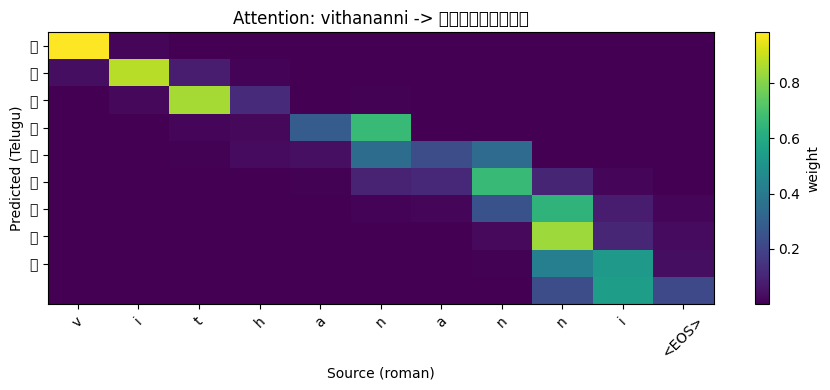


Src: prayaanikulu  True: ప్రయాణికులు  Pred greedy: ప్రయాణికులు  Pred beam: ప్రయాణికులు


/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3114 (\N{TELUGU LETTER PA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Matplotlib currently does not support Telugu natively.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3149 (\N{TELUGU SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3120 (\N{TELUGU LETTER RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3119 (\N{TELUGU LETTER YA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3134 (\N{TELUGU VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3107 (\N{TELUGU LETTER NNA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:1

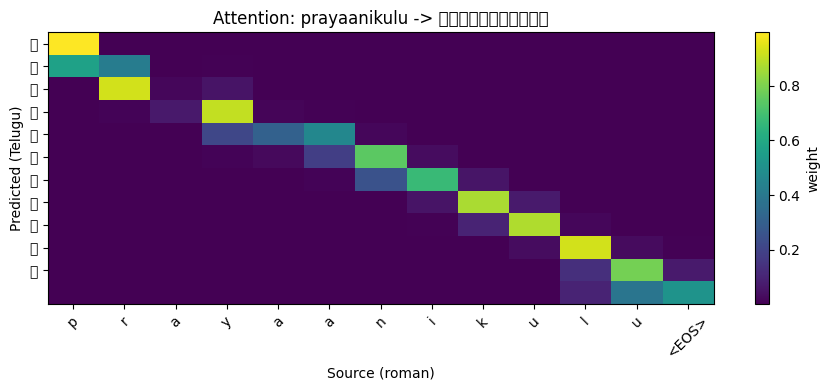


Src: hassan  True: హసన్  Pred greedy: హస్సన్  Pred beam: హస్సన్


/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3129 (\N{TELUGU LETTER HA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Matplotlib currently does not support Telugu natively.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3128 (\N{TELUGU LETTER SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3149 (\N{TELUGU SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3112 (\N{TELUGU LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3129 (\N{TELUGU LETTER HA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not suppor

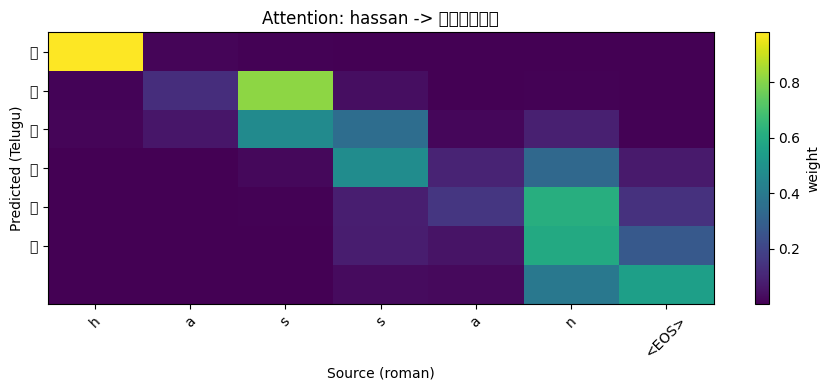


Src: pakshala  True: పక్షాల  Pred greedy: పక్షల  Pred beam: పక్షల


/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3114 (\N{TELUGU LETTER PA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Matplotlib currently does not support Telugu natively.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3093 (\N{TELUGU LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3149 (\N{TELUGU SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3127 (\N{TELUGU LETTER SSA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3122 (\N{TELUGU LETTER LA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3114 (\N{TELUGU LETTER PA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figu

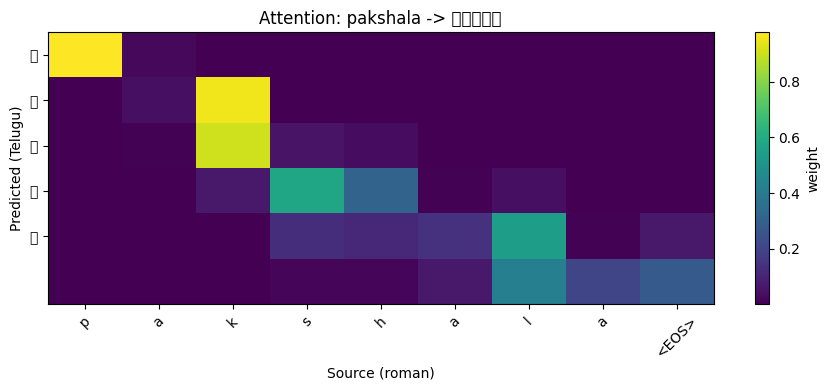


Src: goutham  True: గౌతమ్  Pred greedy: గౌతం  Pred beam: గౌతం


/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3095 (\N{TELUGU LETTER GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Matplotlib currently does not support Telugu natively.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3148 (\N{TELUGU VOWEL SIGN AU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3108 (\N{TELUGU LETTER TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3074 (\N{TELUGU SIGN ANUSVARA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3095 (\N{TELUGU LETTER GA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not 

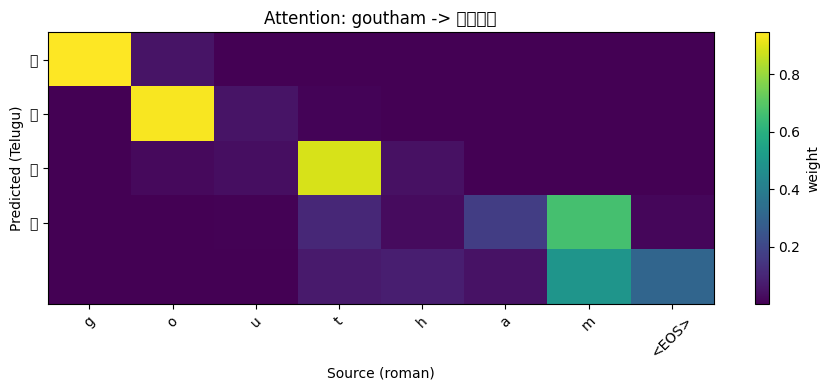

/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3114 (\N{TELUGU LETTER PA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Matplotlib currently does not support Telugu natively.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3137 (\N{TELUGU VOWEL SIGN U}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3120 (\N{TELUGU LETTER RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3134 (\N{TELUGU VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3107 (\N{TELUGU LETTER NNA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3118 (\N{TELUGU LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:


Src: puraanamulanu  True: పురాణములను  Pred greedy: పురాణములను  Pred beam: పురాణములను


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3114 (\N{TELUGU LETTER PA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not support Telugu natively.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3137 (\N{TELUGU VOWEL SIGN U}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3120 (\N{TELUGU LETTER RA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3134 (\N{TELUGU VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-

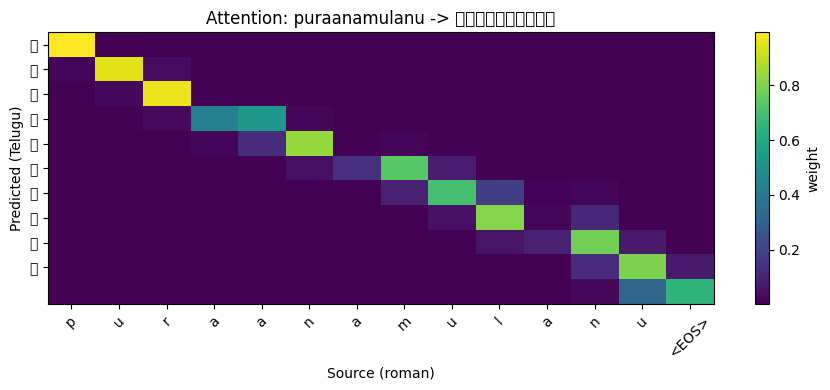

/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3119 (\N{TELUGU LETTER YA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Matplotlib currently does not support Telugu natively.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3138 (\N{TELUGU VOWEL SIGN UU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3112 (\N{TELUGU LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3135 (\N{TELUGU VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3149 (\N{TELUGU SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()



Src: union  True: యూనియన్  Pred greedy: యూనియన్  Pred beam: యూనియన్


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3119 (\N{TELUGU LETTER YA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not support Telugu natively.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3138 (\N{TELUGU VOWEL SIGN UU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3112 (\N{TELUGU LETTER NA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3135 (\N{TELUGU VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-

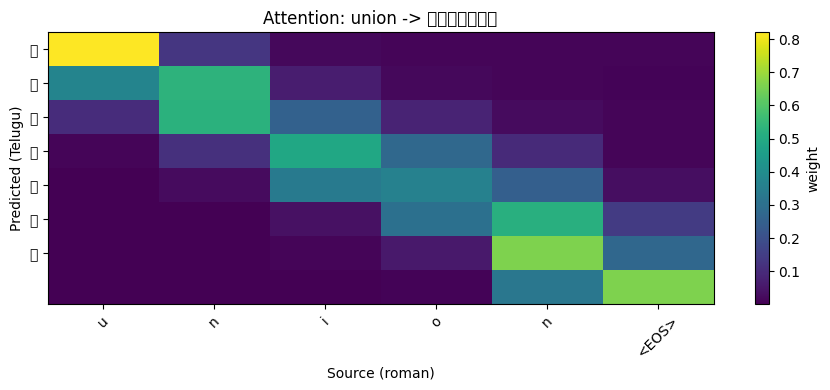

/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3118 (\N{TELUGU LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Matplotlib currently does not support Telugu natively.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3142 (\N{TELUGU VOWEL SIGN E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3110 (\N{TELUGU LETTER DA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3128 (\N{TELUGU LETTER SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3149 (\N{TELUGU SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3137 (\N{TELUGU VOWEL SIGN U}) missing from font(s) DejaVu Sans.
  plt.tight_layout()



Src: medassu  True: మేధస్సు  Pred greedy: మెదస్సు  Pred beam: మెదస్సు


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3118 (\N{TELUGU LETTER MA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not support Telugu natively.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3142 (\N{TELUGU VOWEL SIGN E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3110 (\N{TELUGU LETTER DA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3128 (\N{TELUGU LETTER SA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-pack

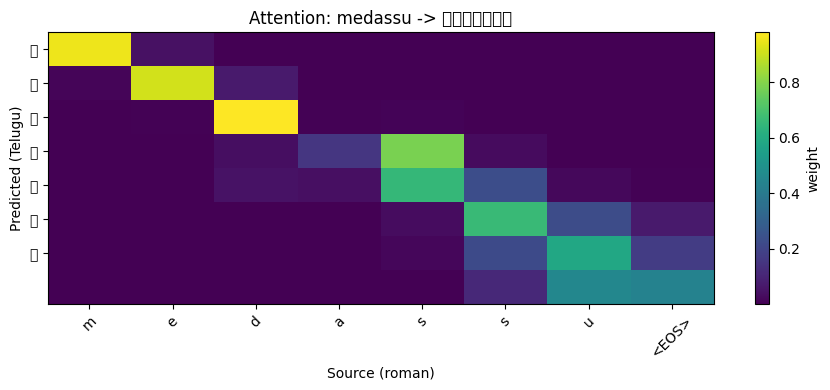

/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3093 (\N{TELUGU LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Matplotlib currently does not support Telugu natively.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3149 (\N{TELUGU SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3119 (\N{TELUGU LETTER YA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3134 (\N{TELUGU VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3074 (\N{TELUGU SIGN ANUSVARA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3103 (\N{TELUGU LETTER TTA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()



Src: kuantum  True: క్వాంటమ్  Pred greedy: క్యాంటం  Pred beam: క్యాంటం


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3093 (\N{TELUGU LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not support Telugu natively.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3149 (\N{TELUGU SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3119 (\N{TELUGU LETTER YA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3134 (\N{TELUGU VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-p

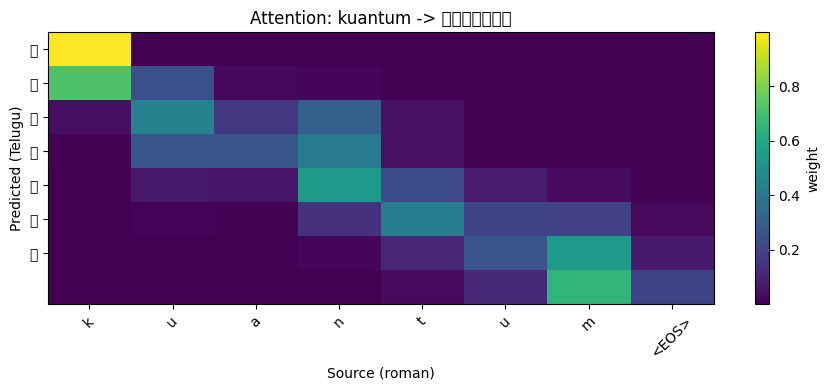


Src: aakaashaannayinaa  True: ఆకాశాన్నయినా  Pred greedy: ఆకాషాన్నయినా  Pred beam: ఆకాషాన్నయినా


/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3078 (\N{TELUGU LETTER AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Matplotlib currently does not support Telugu natively.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3093 (\N{TELUGU LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3134 (\N{TELUGU VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3127 (\N{TELUGU LETTER SSA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3112 (\N{TELUGU LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:119: UserWarning: Glyph 3149 (\N{TELUGU SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_636/773089780.py:1

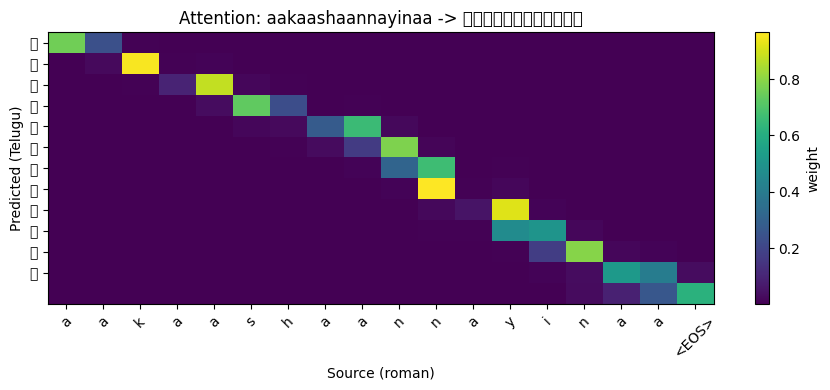

In [15]:
# Cell 11 - Heatmaps for 10 test words (attention only)
for s,t in test_pairs[:10]:
    print(f'\nSrc: {s}  True: {t}  Pred greedy: {translate_greedy_attn(s)}  Pred beam: {beam_search_decode(attn_model, s, beam_size=4)}')
    plot_attention_heatmap(attn_model, s, figsize=(9,4))
